## 1-setup and loading

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("data/raw/imdb_50k.csv")
df["label"] = (df["sentiment"] == "positive").astype(int)
df["n_words"] = df["review"].str.split().str.len()
pl = pd.read_csv("data/raw/pang_lee_2000.csv")
own = pd.read_csv("data/own/own_reviews.csv")
print(df.shape, pl.shape, own.shape)

(50000, 4) (2000, 2) (300, 10)


## 2-structure, balance and duplicates

In [3]:
print(df.isnull().sum().to_dict())
print(df["label"].value_counts().to_dict())
dup = df[df.duplicated(subset="review")]
print(len(dup), dup["label"].value_counts().to_dict())
print(df[df.duplicated(subset="review", keep=False)].groupby("review")["label"].nunique().gt(1).sum())

{'review': 0, 'sentiment': 0, 'label': 0, 'n_words': 0}
{1: 25000, 0: 25000}
418 {0: 302, 1: 116}
0


## 3-review length

In [4]:
print(df.groupby("label")["n_words"].describe().round(1))
print(df["n_words"].quantile([0.95, 0.99]).tolist())

         count   mean    std   min    25%    50%    75%     max
label                                                          
0      25000.0  229.5  164.9   4.0  128.0  174.0  278.0  1522.0
1      25000.0  232.8  177.5  10.0  125.0  172.0  284.0  2470.0
[590.0, 908.0]


## 4-noise and negation 

In [5]:
print(df["review"].str.contains("<br />").mean())
print(df["review"].apply(lambda s: any(ord(c) > 127 for c in s)).mean())
print(df["review"].str.lower().str.contains(r"\b(?:not|no|never|n't)\b|n't").mean())

0.584
0.0932
0.87366


## 5-figure 1

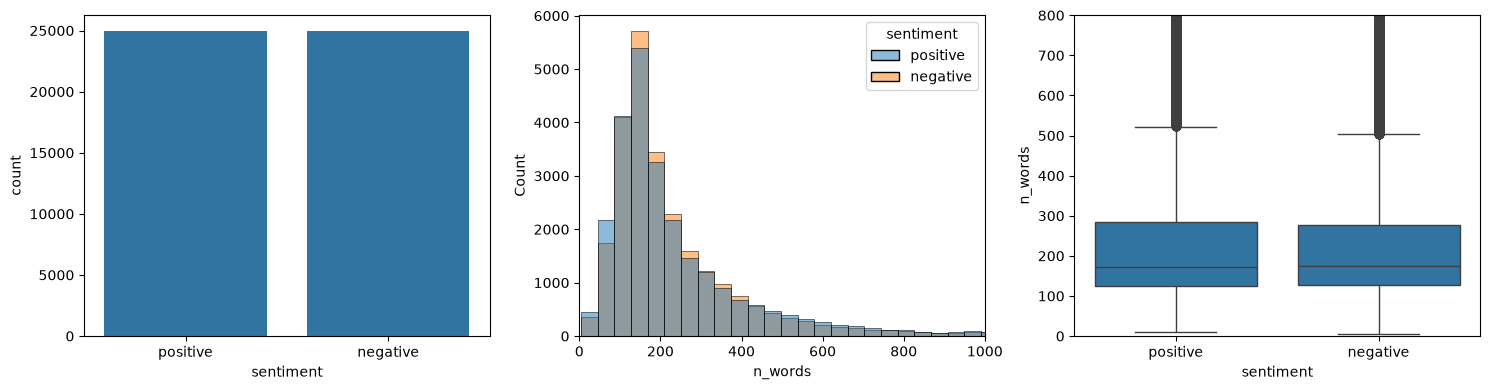

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x="sentiment", data=df, ax=ax[0])
sns.histplot(data=df, x="n_words", hue="sentiment", bins=60, ax=ax[1])
ax[1].set_xlim(0, 1000)
sns.boxplot(x="sentiment", y="n_words", data=df, ax=ax[2])
ax[2].set_ylim(0, 800)
plt.tight_layout()
plt.savefig("figures/01_balance_length.png", dpi=150)
plt.show()

## 6-frequent words and bigrams

In [7]:
txt = df["review"].str.replace(r"<.*?>", " ", regex=True)

def top_ngrams(texts, ngram, n=12):
    cv = CountVectorizer(stop_words="english", ngram_range=ngram)
    X = cv.fit_transform(texts)
    freq = np.asarray(X.sum(axis=0)).ravel()
    vocab = cv.get_feature_names_out()
    return [(vocab[i], int(freq[i])) for i in np.argsort(-freq)[:n]]

for lab in (0, 1):
    sub = txt[df["label"] == lab]
    print(lab, top_ngrams(sub, (1, 1)))
    print(lab, top_ngrams(sub, (2, 2)))

0 [('movie', 50116), ('film', 37595), ('like', 22458), ('just', 21074), ('good', 14728), ('bad', 14726), ('time', 12357), ('really', 12355), ('don', 10622), ('story', 10185), ('people', 9469), ('make', 9354)]
0 [('ve seen', 2307), ('waste time', 1453), ('special effects', 1442), ('don know', 1303), ('looks like', 1259), ('low budget', 1230), ('movie just', 1074), ('look like', 961), ('bad movie', 926), ('year old', 914), ('watch movie', 795), ('sci fi', 770)]
1 [('film', 42110), ('movie', 37854), ('like', 17714), ('good', 15025), ('just', 14109), ('great', 12964), ('story', 12934), ('time', 12752), ('really', 10739), ('people', 8719), ('love', 8692), ('best', 8510)]
1 [('ve seen', 1861), ('don know', 899), ('new york', 855), ('special effects', 807), ('good movie', 762), ('real life', 761), ('years ago', 741), ('10 10', 734), ('great movie', 723), ('year old', 684), ('sci fi', 623), ('low budget', 594)]


## 7-discriminative words and fig 2

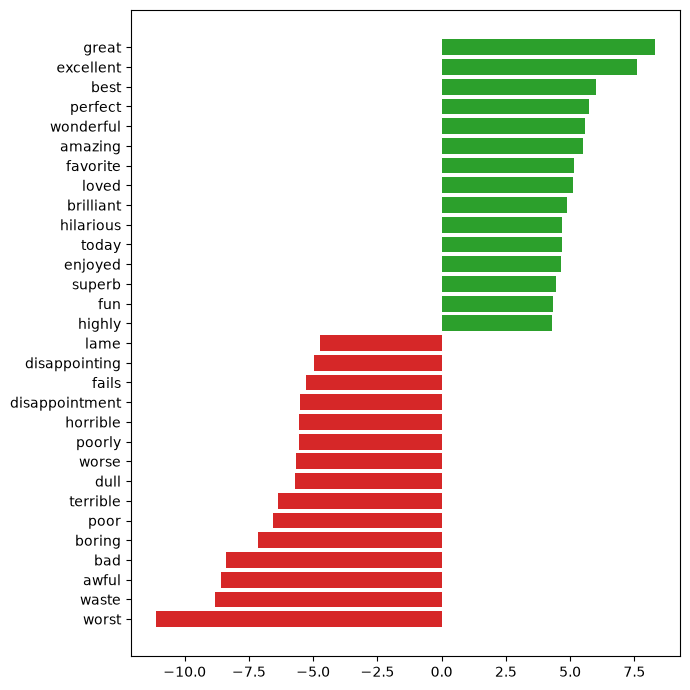

In [8]:
tv = TfidfVectorizer(stop_words="english", max_features=20000, min_df=5)
X = tv.fit_transform(txt)
lr = LogisticRegression(max_iter=1000).fit(X, df["label"])
vocab = tv.get_feature_names_out()
order = np.argsort(lr.coef_[0])
idx = list(order[:15]) + list(order[-15:])

plt.figure(figsize=(7, 7))
plt.barh(vocab[idx], lr.coef_[0][idx], color=["tab:red"] * 15 + ["tab:green"] * 15)
plt.tight_layout()
plt.savefig("figures/02_top_words.png", dpi=150)
plt.show()

## 8-read 20 reviews by hand


In [9]:
for _, r in df.sample(20, random_state=1).iterrows():
    print(r["label"], "|", r["review"][:300], "\n")

0 | With No Dead Heroes you get stupid lines like that as this woefully abysmal action flick needs to be seen to be believed. William Sanders is saved by his buddy Harry Cotter during an extraction in Vietnam but gets himself captured by the enemy. Fast forward ten years and Harry is now a brainwashed R 

0 | I thought maybe... maybe this could be good. An early appearance by the Re-Animator (Jeffery Combs); many homage's to old horror movies; the Troma label on the front this movie could be a gem! I thought wrong.<br /><br />Frightmare is a boring, overplayed, half assed homage to the fright films of y 

0 | An elite American military team which of course happens to include two good looking women and a guy who can't quite grasp teamwork, lots of bats, some terrorists, and a Spetznaz team that acts like the gang that can't shoot straight -- all thrown together in a jumbled plot with mediocre acting. This 

0 | Ridiculous horror film about a wealthy man (John Carradine) dying and leavi

## 9-compare the 3 datasets

In [10]:
def profile(d):
    t = d["review"]
    return {
        "reviews": len(d),
        "pos_share": round(d["label"].mean(), 3),
        "mean_words": round(t.str.split().str.len().mean(), 1),
        "median_words": t.str.split().str.len().median(),
        "html_share": round(t.str.contains("<br />").mean(), 3),
        "negation_share": round(t.str.lower().str.contains(r"\b(?:not|no|never|n't)\b|n't").mean(), 3),
    }

imdb_dedup = df.drop_duplicates(subset="review")
pd.DataFrame({"IMDB": profile(imdb_dedup), "PangLee": profile(pl), "Own": profile(own)}).T

,reviews,pos_share,mean_words,median_words,html_share,negation_share
IMDB,49582.0,0.502,231.4,173.0,0.584,0.874
PangLee,2000.0,0.500,746.3,696.5,0.000,0.982
Own,300.0,0.500,126.8,108.5,0.000,0.743


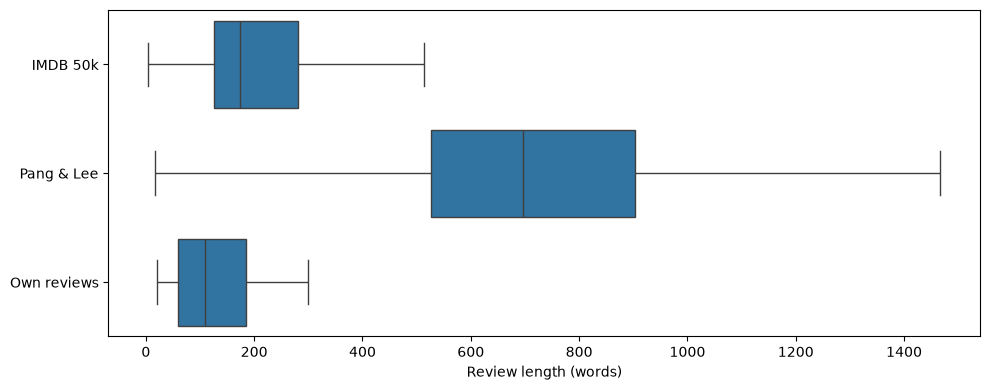

In [11]:
lens = pd.concat([
    pd.DataFrame({"words": imdb_dedup["review"].str.split().str.len(), "dataset": "IMDB 50k"}),
    pd.DataFrame({"words": pl["review"].str.split().str.len(), "dataset": "Pang & Lee"}),
    pd.DataFrame({"words": own["review"].str.split().str.len(), "dataset": "Own reviews"}),
])
plt.figure(figsize=(10, 4))
sns.boxplot(data=lens, x="words", y="dataset", showfliers=False)
plt.xlabel("Review length (words)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("figures/03_length_comparison.png", dpi=150)
plt.show()

## 10-hard cases

In [12]:
print(own.groupby("label")["hard_case"].agg(["sum", "mean"]).round(3))
for _, r in own[own["hard_case"] == 1].head(10).iterrows():
    print(r["label"], r["rating10"], "|", r["review"][:250], "\n")

       sum   mean
label            
0       78  0.520
1       17  0.113
0 4.0 | Allegiant takes the Divergent series in a direction that just doesn’t work, despite having the same strong visuals and solid score as the previous films. The plot feels stretched thin, trying too hard to expand the world while failing to give any rea 

0 1.0 | OK, I gave the first one 10 out of 10 stars...because I am easy and, honestly, the original didn't claim to be anything more than what it delivered. To me that earns all 10 stars. Darker I gave 1 out of 10, because the plot line that it bills itself  

0 1.0 | What a terrible movie, I just gave up halfway through. It might have been OK with a decent script, a competent director, and not having a plank of wood in the lead role, but as that's something very different to what we actually got, we'll never know 

0 1.0 | I think the last film of Lee's watched and enjoyed was his Malcolm X biopic... but to be honest I don't think I really enjoyed the film s

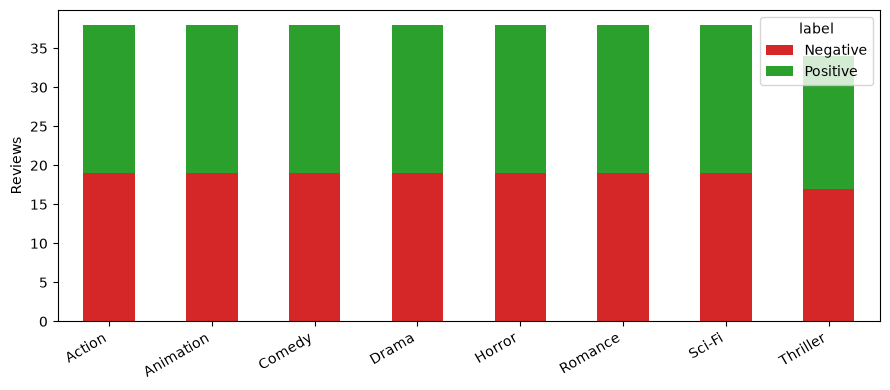

In [13]:
ct = own.groupby(["genre", "label"]).size().unstack(fill_value=0).rename(columns={0: "Negative", 1: "Positive"})
ax = ct.plot(kind="bar", stacked=True, figsize=(9, 4), color=["tab:red", "tab:green"])
ax.set_xlabel("")
ax.set_ylabel("Reviews")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("figures/04_own_genres.png", dpi=150)
plt.show()